# Введение в Machine Learning
 Практические задания на основе набора данных Iris и Intel® oneAPI AI Analytics Toolkit (AI Kit).

In [15]:
from __future__ import print_function
import os
data_path = [ 'data']

import numpy as np
import pandas as pd

filepath = os.sep.join(data_path + ['Iris.csv'])
data = pd.read_csv(filepath)
data.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### Упражнение 1: Загрузка и первичный анализ данных
    Используя библиотеки `pandas` и `numpy`, загрузите файл `Iris_Data.csv` из директории `data`. Выведите на экран:
    - Общее количество строк:

In [16]:
print(data.shape[0])

150


    - Имена всех колонок:

In [17]:
print(data.columns.tolist())

['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


    - Типы данных для каждой колонки:

In [18]:
print(data.dtypes)

Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object


### Упражнение 2: Очистка и преобразование текстовых данных
    Исследуйте значения в колонке `species`.
    Обратите внимание, что все они начинаются с префикса `Iris-`.
    Напишите код для удаления этого префикса во всех строках (чтобы осталось только `setosa`, `versicolor`, `virginica`).

In [19]:
data['Species'] = data.Species.str.replace('Iris-', '')

data.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,setosa
1,2,4.9,3.0,1.4,0.2,setosa
2,3,4.7,3.2,1.3,0.2,setosa
3,4,4.6,3.1,1.5,0.2,setosa
4,5,5.0,3.6,1.4,0.2,setosa


### Упражнение 3: Описательная статистика и размах (range)
    Используя метод `describe()`,
    создайте новую строку в таблице под названием `range`,
    которая вычисляет разницу между максимальным
    и минимальным значением для каждого числового столбца.

In [20]:
stats = data.describe()
stats.loc['range'] = stats.loc['max'] - stats.loc['min']
print(stats)


               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.300000
50%     75.500000       5.800000      3.000000       4.350000      1.300000
75%    112.750000       6.400000      3.300000       5.100000      1.800000
max    150.000000       7.900000      4.400000       6.900000      2.500000
range  149.000000       3.600000      2.400000       5.900000      2.400000


### Упражнение 4: Группировка данных по видам (Среднее и Медиана)
    "Сгруппируйте набор данных по колонке `species`
    и одновременно примените функции **среднего** (`mean`)
    и **медианы** (`median`) ко всем числовым колонкам.

In [21]:
data.groupby('Species').agg(['mean', 'median'])

Id        SepalLengthCm        SepalWidthCm         \
             mean median          mean median         mean median   
Species                                                             
setosa       25.5   25.5         5.006    5.0        3.418    3.4   
versicolor   75.5   75.5         5.936    5.9        2.770    2.8   
virginica   125.5  125.5         6.588    6.5        2.974    3.0   

           PetalLengthCm        PetalWidthCm         
                    mean median         mean median  
Species                                              
setosa             1.464   1.50        0.244    0.2  
versicolor         4.260   4.35        1.326    1.3  
virginica          5.552   5.55        2.026    2.0

### Упражнение 5: Расширенная агрегация с помощью словаря
    Используя метод `agg()` для сгруппированных данных,
    примените следующие правила: для `sepal_length`, `sepal_width` и `petal_width`
    вычислите среднее и медиану, а для `petal_length` — только максимальное значение (`max`).

In [22]:
agg_dict = {field: ['mean', 'median'] for field in data.columns if field not in ['Species', 'PetalLengthCm']}
agg_dict['PetalLengthCm'] = 'max'

print(agg_dict)

data.groupby('Species').agg(agg_dict)

{'Id': ['mean', 'median'], 'SepalLengthCm': ['mean', 'median'], 'SepalWidthCm': ['mean', 'median'], 'PetalWidthCm': ['mean', 'median'], 'PetalLengthCm': 'max'}


Id        SepalLengthCm        SepalWidthCm         \
             mean median          mean median         mean median   
Species                                                             
setosa       25.5   25.5         5.006    5.0        3.418    3.4   
versicolor   75.5   75.5         5.936    5.9        2.770    2.8   
virginica   125.5  125.5         6.588    6.5        2.974    3.0   

           PetalWidthCm        PetalLengthCm  
                   mean median           max  
Species                                       
setosa            0.244    0.2           1.9  
versicolor        1.326    1.3           5.1  
virginica         2.026    2.0           6.9

### Упражнение 6: Визуализация данных с помощью Matplotlib
    Импортируйте `matplotlib.pyplot`
    и постройте диаграмму рассеяния (scatter plot),
    отражающую зависимость `sepal_length` (ось X) от `sepal_width` (ось Y).
    Добавьте подписи осей и заголовок.

Matplotlib is building the font cache; this may take a moment.


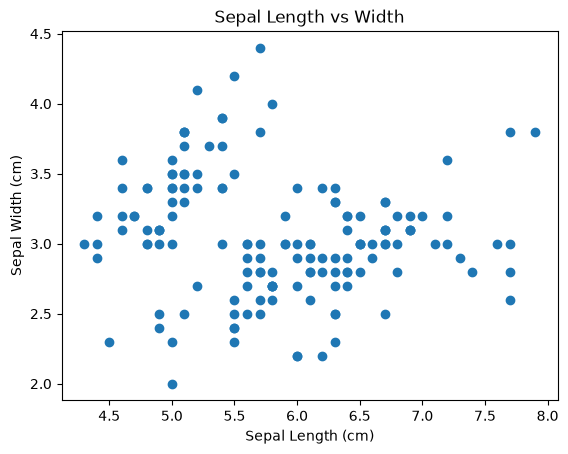

In [23]:
import matplotlib.pyplot as plt
%matplotlib inline

ax = plt.axes()

ax.scatter(data.SepalLengthCm, data.SepalWidthCm)

ax.set(xlabel='Sepal Length (cm)',
       ylabel='Sepal Width (cm)',
       title='Sepal Length vs Width')

### Упражнение 7: Подсчет частоты видов
    "Используйте специальный метод Pandas,
    чтобы узнать точное количество записей
    для каждого отдельного вида в очищенном наборе данных.

In [24]:
data['Species'].value_counts()

Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### Упражнение 8: Ускорение Scikit-learn с помощью Intel® Extension
    Напишите строки кода, которые необходимо выполнить сразу
    после импорта библиотеки `sklearn` для включения оптимизации oneDAL.

In [27]:
import sklearn
from sklearnex import patch_sklearn

patch_sklearn()

ModuleNotFoundError: No module named 'sklearnex'

### Упражнение 9: Фреймворки в Machine Learning
    Основываясь на вводных материалах, объясните,
    почему фреймворки — это больше, чем просто библиотеки,
    и какую материальную пользу приносит оптимизация гиперпараметров.

**Фреймворк** является больше, чем библиотека, потому что библиотеку вызывает разработчик, когда нужно, к примерму **набор каких-то функций**, а фреймворк задаёт **структуру целиком и жизненный цикл приложения**, к примеру цикл обучения модели, код разработчика всего лишь встраивается в неё, по сути работает принцип инверсии управления или **inversion of control** (IoC).

Материальная польза оптимизации гиперпараметров дает возможность **экономить время и деньги на обучение**, так как, чем быстрее сходимость, тем меньше вычислений необходимо. Так же **снижаем риск переобучения или недообучения**, и делает **результаты воспроизводимыми и сравнимыми**.

### Упражнение 10: Предварительные требования курса
    Перечислите как минимум три базовых направления
    (в математике и программировании),
    необходимых для успешного прохождения курса по Machine Learning.

**Во-первых**, линейная алгебра, а именно, векторы, матрицы, матричные операции нужны для понимания работы нейросетей;

**Во-вторых**, теория вероятностей и статистика нужны для понимания что такое распределение, среднее и разброс значений, а также обновление предположений на основе новых данных. Это нужно, чтобы понимать, как модель оценивает свои ошибки и насколько ей можно доверять;

**В-третьих**, Python, структуры данных, как и работа с библиотеками для работы с данными (NumPy, Pandas и тд.);

## Упражнение 11: Продвинутая визуализация распределений с Matplotlib (Гистограммы)
    Используя Matplotlib, постройте фигуру с двумя подграфиками (subplots)
    рядом друг с другом (1 строка, 2 колонки):,
    - На первом графике отобразите гистограмму распределения для `petal_length`.,
    - На втором графике отобразите гистограмму распределения для `petal_width`.,
    Добавьте заголовки и подписи к осям для каждого графика.

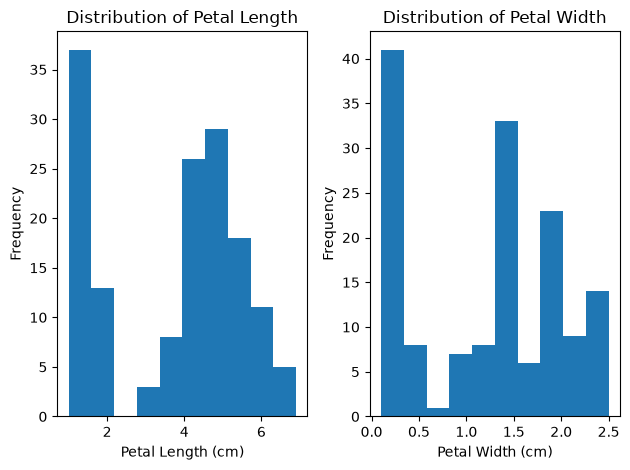

In [26]:
fig, axes = plt.subplots(1, 2)

axes[0].hist(data['PetalLengthCm'])
axes[0].set_title('Distribution of Petal Length')
axes[0].set_xlabel('Petal Length (cm)')
axes[0].set_ylabel('Frequency')

axes[1].hist(data['PetalWidthCm'])
axes[1].set_title('Distribution of Petal Width')
axes[1].set_xlabel('Petal Width (cm)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Упражнение 12: Исследование данных с помощью Seaborn (Pairplot)
    Импортируйте библиотеку `seaborn`
    и постройте парную матрицу графиков (`sns.pairplot`)
    для всего набора данных Iris,
    раскрасив точки в зависимости от вида растения (`species`).

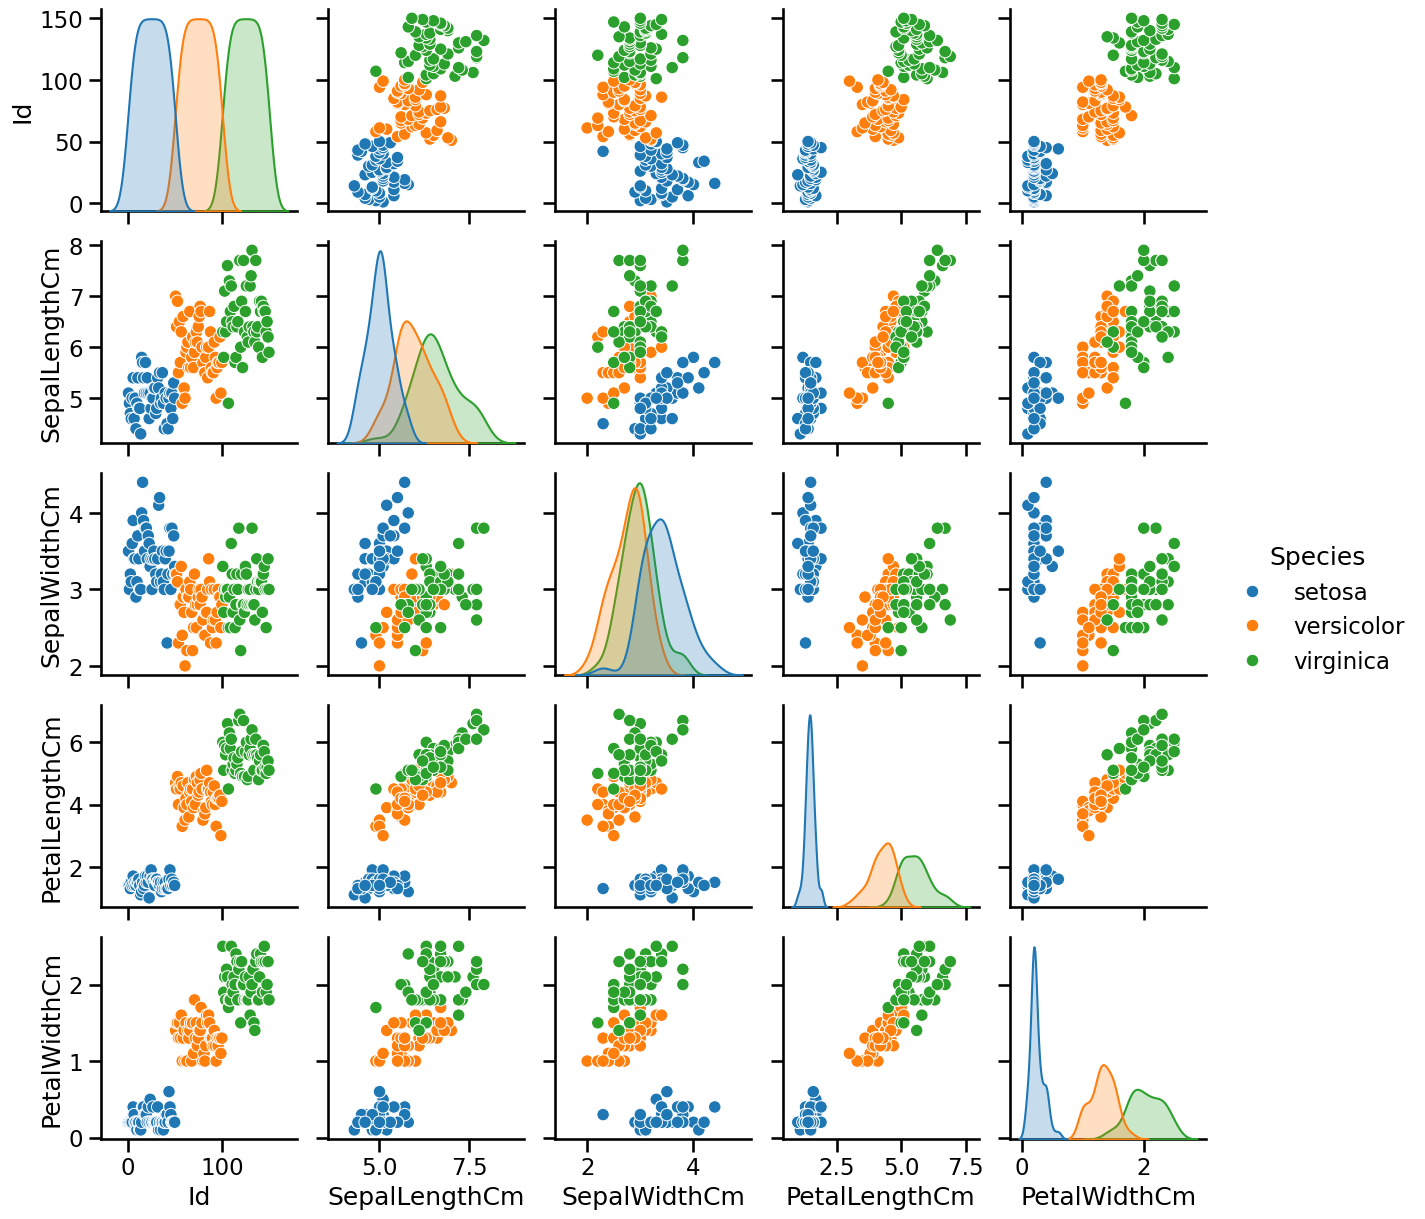

In [ ]:
import seaborn as sns

sns.pairplot(data, hue='Species')
plt.show()

### Упражнение 13: Анализ выбросов через Boxplot (Seaborn)
    Используя библиотеку Seaborn, постройте график «ящик с усами» (`sns.boxplot`),
    чтобы сравнить распределение длины лепестков (`petal_length`) для каждого отдельного вида (`species`).

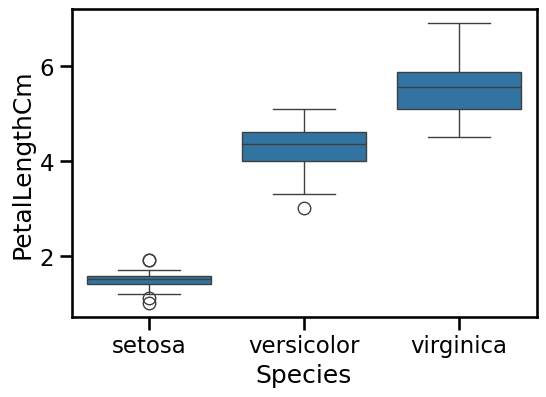

In [ ]:
f = plt.figure(figsize=(6,4))
sns.boxplot(
    x='Species',
    y='PetalLengthCm',
    data=data
)

plt.show()

### Упражнение 14: Тепловая карта корреляций (Seaborn Heatmap)
    Вычислите корреляционную матрицу числовых признаков
    с помощью метода `corr()`, а затем визуализируйте её в виде тепловой карты (`sns.heatmap`),
    включив отображение числовых значений внутри ячеек (`annot=True`).

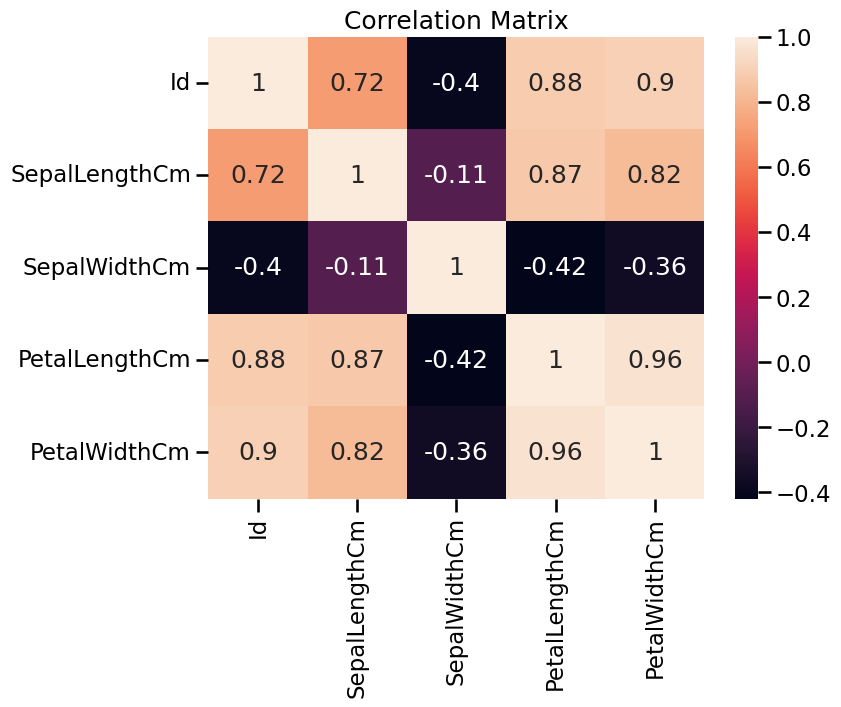

In [ ]:
corr = data.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(corr, annot=True) 

plt.title('Correlation Matrix')
plt.show()